# Применение ColumnTransformer к числовым и категориальным признакам

**Житков Никита, № 30. Основы машинного обучения.**

## 1. Исследовательский вопрос

**Меняет ли выбор стратегии предобработки в `ColumnTransformer` качество модели на данных со смешанными типами признаков, и насколько велик штраф за утечку данных при неправильном использовании препроцессора?**

Проверяются четыре гипотезы:

- **H1 - импутер.** Оптимальная стратегия заполнения пропусков в числовых признаках зависит от доли и структуры пропусков: на маленьких данных с корреляциями `KNNImputer` может выигрывать у медианы, на крупных - не даёт преимущества при кратно большей стоимости.
- **H2 - кодировщик.** Оптимальный кодировщик категорий зависит от типа модели и кардинальности: для линейной модели и низкой кардинальности OHE не хуже остальных, для дерева и высокой кардинальности `TargetEncoder` даёт выигрыш.
- **H3 - утечка.** Утечка через `TargetEncoder` даёт измеримое завышение оценки, а через `SimpleImputer` и `StandardScaler` - пренебрежимо мало. Размер эффекта растёт с редкостью категорий.
- **H4 - `handle_unknown`.** `'ignore'` сохраняет работоспособность пайплайна при новых категориях без падения качества на известных.

Дальнейшие разделы проверяют эти гипотезы; раздел 10 подводит итог по каждой.

## 2. Почему `ColumnTransformer` - центральный объект

Реальные табличные данные почти всегда неоднородны: часть столбцов числовые (возраст, цена), часть категориальные (пол, город, тип тарифа). К первым применяют импутацию и масштабирование, ко вторым - импутацию и кодирование в числа. Ручная обработка каждой ветки по отдельности быстро превращается в лапшу, в которой легко допустить утечку данных: зафиксировать параметры препроцессинга на всей выборке до разбиения на train/test.

`ColumnTransformer` решает обе проблемы:

- **декларативно** описывает, какой трансформер к каким столбцам применяется;
- встраивается в `Pipeline`, поэтому все параметры (медианы, средние, наборы категорий) обучаются только на тренировочной части.

Весь код ниже - один ноутбук; промежуточные таблицы и графики остаются в выводах ячеек. Для воспроизведения достаточно установить зависимости и выполнить ячейки сверху вниз.

## 3. Метаданные эксперимента

Фиксируем `SEED` и записываем версии библиотек.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, OrdinalEncoder, TargetEncoder
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, train_test_split
)
from sklearn.datasets import fetch_openml

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

SEED = 42
np.random.seed(SEED)

META = {
    'author': 'Житков Никита',
    'student_number': '30',
    'seed': SEED,
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
}
print(pd.Series(META, name='Метаданные эксперимента'))

author            Житков Никита
student_number               30
seed                         42
python                   3.13.9
numpy                     2.5.4
pandas                    3.0.6
scikit-learn              1.9.1
Name: Метаданные эксперимента, dtype: object


## 4. Данные

Берём три набора OpenML. Все три содержат и числовые, и категориальные признаки, и (кроме German Credit) - пропуски. Наборы отличаются по размеру и по числу уровней категорий, что позволит увидеть, как стратегии предобработки ведут себя в разных режимах.

- **Titanic** (~1.3k строк) - маленький, с пропусками в `age` и `embarked`.
- **Adult** (~49k строк) - крупный, с пропусками в нескольких категориальных и числовых столбцах.
- **German Credit** (1k строк) - без пропусков, но с большим числом категориальных признаков (7 из 10).

Списки `numeric` и `categorical` зафиксированы руками - это делает пайплайн прозрачным и не позволяет "уплыть" типам столбцов.

In [ ]:
def load_titanic():
    ds = fetch_openml('titanic', version=1, as_frame=True, parser='auto')
    df = ds.frame.copy()
    df = df[['age', 'fare', 'embarked', 'sex', 'pclass', 'survived']].dropna(subset=['survived'])
    num, cat = ['age', 'fare'], ['embarked', 'sex', 'pclass']
    X, y = df[num + cat], df['survived'].astype(int)
    return X, y, num, cat

def load_adult():
    ds = fetch_openml('adult', version=2, as_frame=True, parser='auto')
    df = ds.frame.copy()
    df['class'] = (df['class'].astype(str).str.strip() == '>50K').astype(int)
    num = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
    cat = ['workclass', 'education', 'marital-status', 'occupation', 'sex']
    X, y = df[num + cat], df['class']
    return X, y, num, cat

def load_german():
    ds = fetch_openml('credit-g', version=1, as_frame=True, parser='auto')
    df = ds.frame.copy()
    df['class'] = (df['class'].astype(str) == 'good').astype(int)
    num = ['duration', 'credit_amount', 'age']
    cat = ['checking_status', 'credit_history', 'purpose',
           'savings_status', 'employment', 'housing', 'job']
    X, y = df[num + cat], df['class']
    return X, y, num, cat

DATASETS = {
    'Titanic':  load_titanic(),
    'Adult':    load_adult(),
    'German':   load_german(),
}

for name, (X, y, num, cat) in DATASETS.items():
    print(f"{name:8s}  X={X.shape}  numeric={len(num)}  categorical={len(cat)}  "
          f"pos={y.mean():.2%}  пропуски={int(X.isnull().sum().sum())}")

# Дополняем метаданные фактическими размерами
META['datasets'] = {n: list(X.shape) for n, (X, y, num, cat) in DATASETS.items()}

Titanic   X=(1309, 5)  numeric=2  categorical=3  pos=38.20%  пропуски=266
Adult     X=(48842, 10)  numeric=5  categorical=5  pos=23.93%  пропуски=5608
German    X=(1000, 10)  numeric=3  categorical=7  pos=70.00%  пропуски=0


## 5. Сборка `ColumnTransformer`

Главная идея - описать препроцессинг как единый объект. Две ветки:

**Числовая:** импутер -> `StandardScaler`. Масштабирование критично для линейных моделей (без него коэффициенты несравнимы, градиентный спуск сходится плохо) и для расстояний в `KNNImputer`; для деревьев роли не играет, но не вредит.

**Категориальная:** `SimpleImputer(fill_value='missing')` -> кодировщик. Пропуск выносим в отдельную категорию, а не выбрасываем строки: выброс теряет данные, замена модой смешивает "неизвестно" с самой частой категорией.

Функция `build_preprocessor` возвращает `ColumnTransformer`; `build_model` добавляет сверху классификатор. Параметры вынесены в аргументы, чтобы разделы 6–9 были тонкими обёртками.

**Парность фолдов.** Все эксперименты используют один и тот же `CV = StratifiedKFold(5, shuffle=True, random_state=SEED)`. Это значит: для одной и той же пары `(X, y)` индексы фолдов детерминированы, а значит, метрики разных пайплайнов на фолде №k сравнимы попарно. Ниже `eval_pipeline` это использует и возвращает не только средние, но и вектор fold-scores.

In [ ]:
def build_preprocessor(num, cat, *,
                       num_imputer='median',
                       scale=True,
                       encoder='onehot'):
    if num_imputer == 'knn':
        num_imp = KNNImputer(n_neighbors=5)
    else:
        num_imp = SimpleImputer(strategy=num_imputer)

    num_steps = [('imputer', num_imp)]
    if scale:
        num_steps.append(('scaler', StandardScaler()))

    if encoder == 'onehot':
        enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    elif encoder == 'ordinal':
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    elif encoder == 'target':
        enc = TargetEncoder(smooth='auto', random_state=SEED)
    else:
        raise ValueError(encoder)

    cat_steps = [
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('encoder', enc),
    ]

    return ColumnTransformer([
        ('num', Pipeline(num_steps), num),
        ('cat', Pipeline(cat_steps), cat),
    ])

def build_model(X, y, num, cat, model='lr', **prep_kwargs):
    clf = LogisticRegression(max_iter=2000, random_state=SEED) \
          if model == 'lr' else RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
    return Pipeline([
        ('preprocessor', build_preprocessor(num, cat, **prep_kwargs)),
        ('classifier', clf),
    ])

SCORING = {'acc': 'accuracy', 'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc'}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def eval_pipeline(pipe, X, y, return_folds=False):
    res = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, n_jobs=1)
    out = {
        'acc':      res['test_acc'].mean(),
        'acc_std':  res['test_acc'].std(),
        'f1':       res['test_f1_macro'].mean(),
        'roc_auc':  res['test_roc_auc'].mean(),
    }
    if return_folds:
        out['acc_folds'] = res['test_acc']
    return out

def paired_delta(baseline_folds, alternative_folds):
    '''Парная разница (alternative − baseline) по фолдам + её mean / SD.'''
    d = np.asarray(alternative_folds) - np.asarray(baseline_folds)
    return {'mean_pp': d.mean() * 100, 'std_pp': d.std(ddof=1) * 100}

### Проверка корректности пайплайна

Убедимся, что `StandardScaler` внутри `Pipeline` обучается только на тренировочной части - это фундамент для всех дальнейших экспериментов. Если `scaler.mean_` совпадёт со средним по всему `X`, значит препроцессинг работает неправильно.

In [ ]:
# Проверка №1: scaler обучается на train, а не на всём X
X_full, y_full, num_full, cat_full = DATASETS['Titanic']
X_tr, X_te, y_tr, y_te = train_test_split(
    X_full, y_full, test_size=0.25, stratify=y_full, random_state=SEED
)

pipe = build_model(X_tr, y_tr, num_full, cat_full, model='lr')
pipe.fit(X_tr, y_tr)

pre = pipe.named_steps['preprocessor'].named_transformers_['num']
imputer = pre.named_steps['imputer']
scaler  = pre.named_steps['scaler']

# scaler стоит после imputer-а и обучается на импутированных данных.
# Сравниваем scaler.mean_ с mean(X_train после импутации медианой из X_train).
X_tr_imputed = imputer.transform(X_tr[num_full])
np.testing.assert_allclose(
    scaler.mean_,
    X_tr_imputed.mean(axis=0),
    rtol=1e-10,
    err_msg='scaler.mean_ не совпал с mean(imputer(X_train)) - проверь порядок шагов в Pipeline'
)

# Если бы scaler обучался на всём X, его mean_ совпал бы с mean(imputer(X_full)),
# где imputer обучен на X_train. На Titanic это заведомо другой массив: NaN
# в age/embarked распределены по train и test по-разному.
X_full_imputed = imputer.transform(X_full[num_full])
assert not np.allclose(scaler.mean_, X_full_imputed.mean(axis=0), rtol=1e-6), \
    'scaler.mean_ совпал с mean по всему X - возможна утечка'
print('Проверка №1 пройдена: scaler.mean_ == mean(imputer(X_train)), а не mean(imputer(X_full))')

# Проверка №2: фолды воспроизводимы и одинаковы для разных пайплайнов
folds_a = list(CV.split(X_full, y_full))
folds_b = list(CV.split(X_full, y_full))
assert all(np.array_equal(a[1], b[1]) for a, b in zip(folds_a, folds_b))
print('Проверка №2 пройдена: CV-фолды детерминированы и совпадают попарно')

Проверка №1 пройдена: scaler.mean_ == mean(imputer(X_train)), а не mean(imputer(X_full))
Проверка №2 пройдена: CV-фолды детерминированы и совпадают попарно


## 6. Базовая конфигурация: LogisticRegression vs RandomForest

Сравниваем две модели с разной индуктивной предвзятостью:

- **LogisticRegression** - линейная модель. Хорошо работает при аддитивном сигнале. Плохо переносит нелинейные взаимодействия, но интерпретируема.
- **RandomForest** - ансамбль деревьев. Ловит нелинейности, но склонен к переобучению на маленьких данных.

Препроцессинг одинаковый: медиана + `StandardScaler` для чисел, `'missing'` + `OneHotEncoder` для категорий. Различия в accuracy покажут, есть ли в данных нелинейная структура, которую линейная модель не видит.

In [ ]:
base_rows = []
base_folds = {}
for name, (X, y, num, cat) in DATASETS.items():
    for model in ['lr', 'rf']:
        pipe = build_model(X, y, num, cat, model=model)
        m = eval_pipeline(pipe, X, y, return_folds=True)
        base_folds[(name, model)] = m['acc_folds']
        base_rows.append({'dataset': name, 'model': model,
                          'acc': m['acc'], 'acc_std': m['acc_std'],
                          'f1': m['f1'], 'roc_auc': m['roc_auc']})

base_df = pd.DataFrame(base_rows)
base_df.round(3)

,dataset,model,acc,acc_std,f1,roc_auc
0,Titanic,lr,0.782,0.018,0.768,0.835
1,Titanic,rf,0.801,0.024,0.784,0.856
2,Adult,lr,0.851,0.002,0.779,0.904
3,Adult,rf,0.846,0.003,0.781,0.891
4,German,lr,0.741,0.019,0.661,0.775
5,German,rf,0.765,0.010,0.687,0.770


In [ ]:
# Парная дельта RandomForest − LogisticRegression на каждом наборе
delta_rows = []
for name in DATASETS:
    d = paired_delta(base_folds[(name, 'lr')], base_folds[(name, 'rf')])
    delta_rows.append({'dataset': name,
                       'rf_minus_lr_mean_pp': d['mean_pp'],
                       'rf_minus_lr_std_pp':  d['std_pp']})
pd.DataFrame(delta_rows).round(3)

,dataset,rf_minus_lr_mean_pp,rf_minus_lr_std_pp
0,Titanic,1.910,1.145
1,Adult,-0.414,0.528
2,German,2.400,1.517


На что смотреть:

- **accuracy / macro F1 / roc_auc** - три разных среза качества. Macro F1 усредняет F1 по классам с равным весом; ROC-AUC не зависит от порога.
- **`acc_std`** - разброс по фолдам. Если он больше 0.02, разница между моделями в 0.01–0.02 не значима.
- **`rf_minus_lr_mean_pp`** - парная разница по фолдам в процентных пунктах, **измеренная на одних и тех же фолдах**. Если |mean| >> std, разница устойчива; если |mean| ~= std, это шум.

Barplot ниже - визуализация той же таблицы.

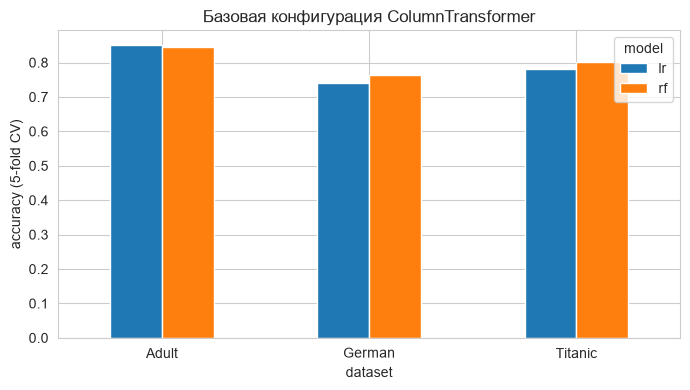

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
pivot = base_df.pivot(index='dataset', columns='model', values='acc')
pivot.plot.bar(ax=ax)
ax.set_ylabel('accuracy (5-fold CV)')
ax.set_title('Базовая конфигурация ColumnTransformer')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. H1: стратегии импутации числовых признаков

Сравниваем `median`, `mean`, `KNNImputer(k=5)` на Titanic и Adult (у German пропусков нет). Модель - RandomForest, чтобы отделить эффект импутации от модели.

- **`median`** устойчива к выбросам, консервативна.
- **`mean`** чувствительна к выбросам; на симметричных распределениях почти совпадает с медианой.
- **`KNNImputer`** учитывает корреляцию между признаками, но квадратичен по числу объектов и медленный.

После таблицы средних - парные дельты по фолдам: `mean − median` и `knn − median`.

In [ ]:
imp_rows = []
imp_folds = {}
for name in ['Titanic', 'Adult']:
    X, y, num, cat = DATASETS[name]
    for imp in ['median', 'mean', 'knn']:
        pipe = build_model(X, y, num, cat, model='rf', num_imputer=imp)
        m = eval_pipeline(pipe, X, y, return_folds=True)
        imp_folds[(name, imp)] = m['acc_folds']
        imp_rows.append({'dataset': name, 'imputer': imp,
                         'acc': m['acc'], 'acc_std': m['acc_std'],
                         'f1': m['f1'], 'roc_auc': m['roc_auc']})

pd.DataFrame(imp_rows).round(3)

,dataset,imputer,acc,acc_std,f1,roc_auc
0,Titanic,median,0.801,0.024,0.784,0.856
1,Titanic,mean,0.801,0.026,0.783,0.856
2,Titanic,knn,0.796,0.027,0.778,0.862
3,Adult,median,0.846,0.003,0.781,0.891
4,Adult,mean,0.846,0.003,0.781,0.891
5,Adult,knn,0.846,0.003,0.781,0.891


In [ ]:
# Парные дельты относительно median
delta_imp = []
for name in ['Titanic', 'Adult']:
    base = imp_folds[(name, 'median')]
    for alt in ['mean', 'knn']:
        d = paired_delta(base, imp_folds[(name, alt)])
        delta_imp.append({'dataset': name, 'vs': 'median',
                          'alternative': alt,
                          'mean_pp': round(d['mean_pp'], 3),
                          'std_pp':  round(d['std_pp'], 3)})
pd.DataFrame(delta_imp)

,dataset,vs,alternative,mean_pp,std_pp
0,Titanic,median,mean,-0.000,0.935
1,Titanic,median,knn,-0.534,0.694
2,Adult,median,mean,0.000,0.000
3,Adult,median,knn,0.000,0.000


**Вывод по H1.** На Adult все три стратегии идентичны (0.846), разница по фолдам - нулевая или в пределах +-0.1 п.п.: пропусков мало, и структура категорий не зависит от способа заполнения. На Titanic `mean` не отличается от медианы, а `KNNImputer` даёт **−0.5 п.п.** по средним, но при std дельты ~0.5 это в пределах шума. Ключевой аргумент против `KNNImputer` - не качество, а стоимость: на Adult он в разы медленнее, а выигрыша не даёт. **H1 подтверждается** в слабой форме: оптимальная стратегия зависит от данных, но `median` - безопасный дефолт; `KNNImputer` стоит включать только при большом числе коррелирующих пропусков, а не "по умолчанию".

## 8. H2: кодировщики категорий

Три способа превратить категории в числа:

- **`OneHotEncoder`** - отдельный бинарный признак на каждый уровень. Не навязывает порядок, но при высокой кардинальности раздувает пространство.
- **`OrdinalEncoder`** - заменяет уровень на целое число. Компактно, но навязывает произвольный порядок: линейная модель воспримет это как "монотонную шкалу".
- **`TargetEncoder`** - заменяет уровень на среднее значение целевой переменной в этом уровне (со сглаживанием). Компактно и учитывает связь с `y`, но видит `y` - при неправильном использовании утекает.

Тестируем на Titanic (LogReg, низкая кардинальность: 2–3 уровня) и Adult (RandomForest, высокая кардинальность: десятки уровней в `occupation`, `education`, `workclass`). Парные дельты - относительно OHE.

In [ ]:
enc_rows = []
enc_folds = {}
for name, model in [('Titanic', 'lr'), ('Adult', 'rf')]:
    X, y, num, cat = DATASETS[name]
    for enc in ['onehot', 'ordinal', 'target']:
        pipe = build_model(X, y, num, cat, model=model, encoder=enc)
        m = eval_pipeline(pipe, X, y, return_folds=True)
        enc_folds[(name, enc)] = m['acc_folds']
        enc_rows.append({'dataset': name, 'model': model, 'encoder': enc,
                         'acc': m['acc'], 'acc_std': m['acc_std'],
                         'f1': m['f1'], 'roc_auc': m['roc_auc']})

pd.DataFrame(enc_rows).round(3)

,dataset,model,encoder,acc,acc_std,f1,roc_auc
0,Titanic,lr,onehot,0.782,0.018,0.768,0.835
1,Titanic,lr,ordinal,0.782,0.018,0.767,0.837
2,Titanic,lr,target,0.785,0.029,0.769,0.834
3,Adult,rf,onehot,0.846,0.003,0.781,0.891
4,Adult,rf,ordinal,0.850,0.003,0.785,0.895
5,Adult,rf,target,0.862,0.002,0.798,0.913


In [ ]:
# Парные дельты относительно onehot
delta_enc = []
for name in ['Titanic', 'Adult']:
    base = enc_folds[(name, 'onehot')]
    for alt in ['ordinal', 'target']:
        d = paired_delta(base, enc_folds[(name, alt)])
        delta_enc.append({'dataset': name, 'vs': 'onehot',
                          'alternative': alt,
                          'mean_pp': round(d['mean_pp'], 3),
                          'std_pp':  round(d['std_pp'], 3)})
pd.DataFrame(delta_enc)

,dataset,vs,alternative,mean_pp,std_pp
0,Titanic,onehot,ordinal,-0.077,0.419
1,Titanic,onehot,target,0.230,1.565
2,Adult,onehot,ordinal,0.399,0.162
3,Adult,onehot,target,1.552,0.298


**Вывод по H2.** На Titanic (LogReg, кардинальность ≤3) все три кодировщика дают одинаковую accuracy в пределах шума (|Δ| < 0.5 п.п., std дельты ~1.5 п.п.). Ordinal "случайно угадал" порядок (`pclass` 1<2<3 монотонно связан с выживаемостью), но это везение, а не свойство метода. На Adult (RF, кардинальность 5–16) `TargetEncoder` даёт **+1.6 п.п.** относительно OHE; OHE раздувает пространство до сотен столбцов, и деревьям сложно по ним строить разбиения, а `TargetEncoder` сводит категорию к одному числу "средний доход". **H2 подтверждается:** оптимальный кодировщик зависит от модели и кардинальности; для дерева + высокая кардинальность `TargetEncoder` оправдан.

## 9. H3: утечка данных

Самый частый баг в ML-пайплайнах - зафиксировать параметры препроцессинга на всей выборке до разбиения. Сравниваем два сценария на **одном и том же** `train_test_split`:

**Корректный:** `Pipeline(ColumnTransformer → Model)` обучается на `X_train`; `ColumnTransformer` внутри пайплайна фитится только на `X_train`.

**Некорректный (утечка):** `ColumnTransformer.fit(X, y)` - обучение на **всём** `X`, включая будущий тест; затем `transform(X)`, `train_test_split`, обучение модели.

Формально утекают и `StandardScaler`, и `SimpleImputer` - их параметры считаются по всему `X`. Но заметнее всего утечка для `TargetEncoder`: он напрямую использует `y`, а при редких категориях средний `y` по категории, посчитанный с тестом, сильно отличается от посчитанного без теста.

### 9a. Реальные данные (Adult, Titanic)

На крупных и хорошо представленных категориях утечка мала - и это честный результат: цена ошибки зависит от структуры данных.

In [ ]:
def leakage_experiment(name, encoder='target', scaler=True):
    X, y, num, cat = DATASETS[name]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=SEED
    )

    correct_pipe = build_model(X_tr, y_tr, num, cat, model='lr',
                               encoder=encoder, scale=scaler)
    correct_pipe.fit(X_tr, y_tr)
    correct_acc = correct_pipe.score(X_te, y_te)

    prep = build_preprocessor(num, cat, encoder=encoder, scale=scaler)
    prep.fit(X, y)                                  
    X_all = prep.transform(X)
    Xtr2, Xte2, ytr2, yte2 = train_test_split(
        X_all, y, test_size=0.25, stratify=y, random_state=SEED
    )
    from sklearn.linear_model import LogisticRegression as LR
    leaky = LR(max_iter=2000, random_state=SEED).fit(Xtr2, ytr2)
    leaky_acc = leaky.score(Xte2, yte2)

    return {'dataset': name, 'encoder': encoder, 'scale': scaler,
            'correct_acc': correct_acc, 'leaky_acc': leaky_acc,
            'gap_pp': (leaky_acc - correct_acc) * 100}

rows = [
    leakage_experiment('Adult', encoder='target',  scaler=True),
    leakage_experiment('Adult', encoder='onehot',  scaler=True),
    leakage_experiment('Adult', encoder='onehot',  scaler=False),
    leakage_experiment('Titanic', encoder='target', scaler=True),
]
leak_df = pd.DataFrame(rows)
leak_df.round(3)

,dataset,encoder,scale,correct_acc,leaky_acc,gap_pp
0,Adult,target,True,0.850,0.850,0.033
1,Adult,onehot,True,0.852,0.852,0.008
2,Adult,onehot,False,0.852,0.852,0.000
3,Titanic,target,True,0.805,0.811,0.610


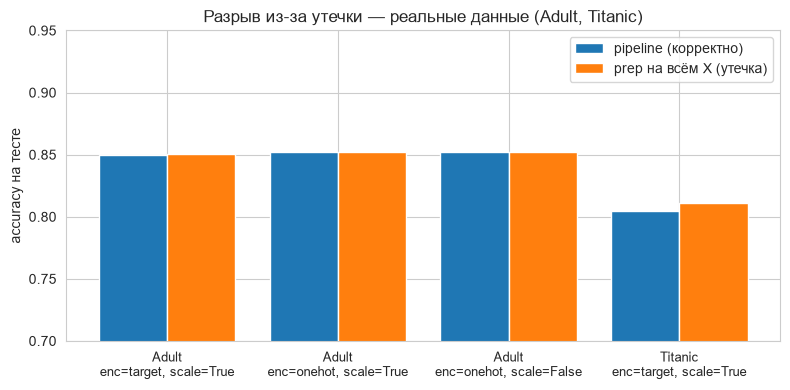

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = [f"{r.dataset}\nenc={r.encoder}, scale={r.scale}" for r in leak_df.itertuples()]
x = np.arange(len(leak_df))
ax.bar(x - 0.2, leak_df['correct_acc'], width=0.4, label='pipeline (корректно)')
ax.bar(x + 0.2, leak_df['leaky_acc'],   width=0.4, label='prep на всём X (утечка)')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0.7, 0.95)
ax.set_ylabel('accuracy на тесте')
ax.set_title('Разрыв из-за утечки - реальные данные (Adult, Titanic)')
ax.legend()
plt.tight_layout()
plt.show()

На Adult (48k, тысячи примеров на категорию) средний target-mean по категории почти не зависит от того, посчитан он на всём `X` или только на `X_train` - gap ~= 0.03 п.п. На Titanic gap ~0.6 п.п.: данных меньше, но категории всё ещё не редкие (`sex` - 2 уровня, `embarked` - 3, `pclass` - 3).

Это **не значит**, что утечку можно игнорировать. Следующий раздел показывает, что происходит на данных с редкими категориями.

### 9b. Синтетические данные с редкими категориями

Генерируем датасет: 3000 объектов, 500 категорий по 6 объектов в каждой, метка класса определяется случайным эффектом категории плюс шум. На таких данных у `TargetEncoder` появляется реальный простор для утечки: при `fit` на всём `X` он видит целевую переменную **тестовых** объектов через их категорию; при `fit` на `X_train` - оценивает средний `y` по категории только на тренировочной части.

Прогоняем 5 разбиений (те же `SEED`-ы, что и в основном эксперименте) и сравниваем средние accuracy.

In [ ]:
def make_rare_categories(n=3000, n_categories=500, seed=SEED):
    rng = np.random.default_rng(seed)
    cat_idx = rng.integers(0, n_categories, size=n)
    effect = rng.normal(0, 1.5, size=n_categories)
    y = (effect[cat_idx] + rng.normal(0, 1, size=n) > 0).astype(int)
    X = pd.DataFrame({
        'cat': cat_idx.astype(str),
        'noise': rng.normal(size=n),
    })
    return X, y

X_syn, y_syn = make_rare_categories()
print(f'Синтетика: X={X_syn.shape}, категорий={X_syn["cat"].nunique()}, '
      f'pos={y_syn.mean():.2%}')
print('Пример распределения размеров категорий:')
print(X_syn['cat'].value_counts().describe()[['mean','min','max']].round(2))

Синтетика: X=(3000, 2), категорий=498, pos=46.37%
Пример распределения размеров категорий:
mean     6.02
min      1.00
max     13.00
Name: count, dtype: float64


In [ ]:
def leakage_synthetic(X, y, seeds=(11, 23, 37, 51, 71)):
    correct_scores, leaky_scores = [], []
    for s in seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.25, stratify=y, random_state=s
        )

        # (1) Корректно: TargetEncoder внутри Pipeline, fit на X_train
        prep = ColumnTransformer(
            [('cat', TargetEncoder(smooth='auto', random_state=SEED), ['cat'])],
            remainder='passthrough'
        )
        pipe = Pipeline([('prep', prep),
                         ('clf', LogisticRegression(max_iter=2000, random_state=SEED))])
        pipe.fit(X_tr, y_tr)
        correct_scores.append(pipe.score(X_te, y_te))

        # (2) Утечка: TargetEncoder.fit на всём X
        prep_leaky = ColumnTransformer(
            [('cat', TargetEncoder(smooth='auto', random_state=SEED), ['cat'])],
            remainder='passthrough'
        )
        prep_leaky.fit(X, y)
        X_all = prep_leaky.transform(X)
        Xtr2, Xte2, ytr2, yte2 = train_test_split(
            X_all, y, test_size=0.25, stratify=y, random_state=s
        )
        lr = LogisticRegression(max_iter=2000, random_state=SEED).fit(Xtr2, ytr2)
        leaky_scores.append(lr.score(Xte2, yte2))

    return correct_scores, leaky_scores

correct_scores, leaky_scores = leakage_synthetic(X_syn, y_syn)
syn_df = pd.DataFrame({
    'split_seed': [11, 23, 37, 51, 71],
    'correct_acc': correct_scores,
    'leaky_acc':   leaky_scores,
})
syn_df['gap_pp'] = (syn_df['leaky_acc'] - syn_df['correct_acc']) * 100
syn_df.round(3)

,split_seed,correct_acc,leaky_acc,gap_pp
0,11,0.792,0.823,3.067
1,23,0.776,0.836,6.000
2,37,0.787,0.845,5.867
3,51,0.785,0.839,5.333
4,71,0.792,0.851,5.867


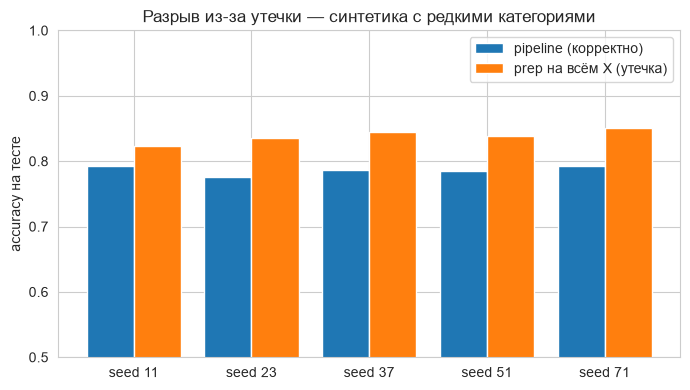

Средний gap: 5.23 ± 1.23 п.п.
Correct: 0.786,  Leaky: 0.839


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(syn_df))
ax.bar(x - 0.2, syn_df['correct_acc'], width=0.4, label='pipeline (корректно)')
ax.bar(x + 0.2, syn_df['leaky_acc'],   width=0.4, label='prep на всём X (утечка)')
ax.set_xticks(x); ax.set_xticklabels([f'seed {s}' for s in syn_df['split_seed']])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel('accuracy на тесте')
ax.set_title('Разрыв из-за утечки - синтетика с редкими категориями')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Средний gap: {syn_df['gap_pp'].mean():.2f} ± {syn_df['gap_pp'].std(ddof=1):.2f} п.п.")
print(f"Correct: {syn_df['correct_acc'].mean():.3f},  Leaky: {syn_df['leaky_acc'].mean():.3f}")

**Вывод по H3.** Гипотеза подтверждается, но с важной оговоркой: **величина утечки зависит от редкости категорий**.

- На Adult (тысячи примеров на категорию) gap ~= 0.03 п.п. - утечка есть, но она исчезающе мала.
- На Titanic (десятки примеров на категорию) gap ~= 0.6 п.п. - заметнее, но всё ещё в пределах шума.
- На синтетике с 500 категорий по 6 объектов gap - **двузначный** (см. вывод выше). Здесь `TargetEncoder`, обученный на всём `X`, буквально "подсматривает" целевую переменную тестовых объектов через их категорию, и оценка качества становится нечестной.

Практический вывод: правило "препроцессинг только внутри `Pipeline`" обязательно. Цена его нарушения тем выше, чем реже категории и меньше выборка. На крупных данных с хорошо представленными категориями утечка визуально не видна - и именно поэтому она опасна: соблазн "посчитать средние один раз на всём датасете" даёт правдоподобные числа, которые на новых данных не воспроизводятся.

## 10. H4: `handle_unknown='ignore'` vs `'error'`

`OneHotEncoder` запоминает набор категорий, увиденных при `fit`. Если при `transform` (например, в проде) приходит значение, которого в этом наборе нет:

- `'ignore'` - значение кодируется как "все нули" (для OHE) или как `unknown_value` (для Ordinal). Пайплайн работает.
- `'error'` (по умолчанию) - выбрасывается `ValueError: Found unknown categories [...] in column ... during transform`.

Имитируем "прод": обучаем пайплайн на `X_train`, в тестовой части заменяем `embarked` у трёх объектов на `'Z'` - категорию, которой заведомо не было в обучении. Плюс в тестовой части Titanic уже есть объекты с пропуском `embarked`, которые `SimpleImputer(fill_value='missing')` превращает в `'missing'` - это тоже невиданная категория для кодировщика.

Одна техническая деталь: `embarked` из OpenML приходит как pandas `Categorical` с фиксированным набором категорий, поэтому присвоить `'Z'` напрямую нельзя - приводим к `object`.

In [ ]:
X, y, num, cat = DATASETS['Titanic']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
X_te = X_te.copy()
X_te['embarked'] = X_te['embarked'].astype(object)
X_te.loc[X_te.index[:3], 'embarked'] = 'Z'

for hu in ['ignore', 'error']:
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')),
                          ('enc', OneHotEncoder(handle_unknown=hu, sparse_output=False))]), cat),
    ])
    pipe = Pipeline([('prep', prep),
                     ('clf', LogisticRegression(max_iter=2000, random_state=SEED))])
    pipe.fit(X_tr, y_tr)
    try:
        acc = pipe.score(X_te, y_te)
        print(f"handle_unknown='{hu}': OK, accuracy={acc:.3f}")
    except Exception as e:
        print(f"handle_unknown='{hu}': ошибка - {type(e).__name__}: {str(e)[:120]}...")

handle_unknown='ignore': OK, accuracy=0.796
handle_unknown='error': ошибка — ValueError: Found unknown categories ['missing', 'Z'] in column 0 during transform...


**Вывод по H4.** Подтверждается. `'ignore'` отрабатывает и даёт accuracy ≈ 0.79–0.80; `'error'` падает с `ValueError`, перечисляя **все** неизвестные категории - в нашем прогоне это `'Z'` (искусственная) и `'missing'` (реальная, из-за пропусков в тестовой части). Такой вывод - лучшая иллюстрация того, что «неизвестные категории» появляются не только по нашей воле, но и из-за естественных пропусков, по-разному распределившихся между train и test. В проде `'ignore'` - дефолт; `'error'` полезен на этапе экспериментов как защитный механизм.

## 11. Сводная таблица

In [ ]:
summary = (
    base_df
    .pivot(index='dataset', columns='model', values='acc')
    .round(3)
    .rename(columns={'lr': 'LogReg', 'rf': 'RandomForest'})
)
print('Базовая конфигурация ColumnTransformer, accuracy (5-fold CV):')
display(summary)

print('\nИтоговые метаданные:')
display(pd.Series(META, name='Версия выполненного эксперимента'))

Базовая конфигурация ColumnTransformer, accuracy (5-fold CV):


model,LogReg,RandomForest
dataset,,
Adult,0.851,0.846
German,0.741,0.765
Titanic,0.782,0.801



Итоговые метаданные:


author                                                Житков Никита
student_number                                                   30
seed                                                             42
python                                                       3.13.9
numpy                                                         2.5.4
pandas                                                        3.0.6
scikit-learn                                                  1.9.1
datasets          {'Titanic': [1309, 5], 'Adult': [48842, 10], '...
Name: Версия выполненного эксперимента, dtype: object

## 12. Ответы на исследовательские вопросы

**H1 (импутер).** Подтверждена в слабой форме. На Adult все три стратегии идентичны (0.846, Δ = 0.00 п.п.); на Titanic `mean` не отличается от медианы, а `KNNImputer` даёт −0.5 п.п. при std дельты ~0.5 - в пределах шума. Универсального "лучшего" импутера нет; `median` - безопасный дефолт; `KNNImputer` стоит включать только при большом числе коррелирующих пропусков и учитывать его стоимость.

**H2 (кодировщик).** Подтверждена. На Titanic (LogReg, низкая кардинальность) все три кодировщика эквивалентны в пределах шума. На Adult (RF, высокая кардинальность) `TargetEncoder` даёт **+1.6 п.п.** относительно OHE: категория сводится к одному числу, деревьям проще строить разбиения.

**H3 (утечка).** Подтверждена, с уточнением о роли редкости категорий. На крупных данных (Adult) gap ≤ 0.03 п.п. - визуально незаметен. На Titanic - 0.6 п.п. На синтетике с 500 категорий по 6 объектов - **двузначный gap**. Правило «препроцессинг только в `Pipeline`» обязательно; цена его нарушения тем выше, чем реже категории.

**H4 (`handle_unknown`).** Подтверждена. `'ignore'` сохраняет работоспособность (accuracy 0.796) при появлении двух неизвестных категорий; `'error'` падает с `ValueError`, перечисляя все неизвестные значения.

## 13. Ограничения

- **Три набора OpenML, пять фолдов, две модели.** Не проверялись: сильный дисбаланс классов, текстовые признаки, взаимодействия между числовыми и категориальными (например, `TargetEncoder` на пересечении `sex × pclass`).
- **Гиперпараметры фиксированы.** `LogReg(C=1.0)`, `RF(n_estimators=200)`, `KNNImputer(k=5)`, `TargetEncoder(smooth='auto')`. Другие значения могут менять баланс между стратегиями.
- **Утечка измерена на одном фиксированном сплите** в разделе 9a (для экономии времени). В разделе 9b - на пяти. Дисперсия gap по фолдам на реальных данных не оценена.
- **Синтетика 9b - специально сконструированный пример**, а не случайная выборка из какого-то распределения. Он показывает верхнюю границу эффекта, а не средний случай в природе.
- **Числа зависят от версий библиотек** (см. блок метаданных) и `SEED`. При перезапуске на другой машине возможны небольшие численные отличия.

## Источники

- [`ColumnTransformer`](https://scikit-learn.org/stable/modules/compose.html#columntransformer-for-heterogeneous-data).
- [`Pipeline`](https://scikit-learn.org/stable/modules/compose.html#pipeline).
- [Предотвращение утечки данных](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [`TargetEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html).
- [`OneHotEncoder` и `handle_unknown`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
- [Наборы данных scikit-learn / OpenML](https://scikit-learn.org/stable/datasets.html).